## Library Imports
1. `numpy`: Used for high-performance numerical operations and outlier filtering.
2. `pandas`: Used for data loading, manipulation, and cleaning.
3. `matplotlib.pyplot`: Used for creating basic statistical plots.
4. `seaborn`: Used for advanced statistical data visualizations and correlation heatmaps.
5. `plotly.express`: Used for building interactive geospatial maps of Cairo districts.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

### Data Loading and Initial Inspection

- Load the rental and district datasets into Pandas DataFrames.
- Check dataset dimensions and data types to understand their structure.
- Identify and remove duplicate rows to avoid redundant records and ensure data consistency.
- Check missing values to identify potential data quality issues that may require further cleaning.

**Expected Output:**
- Dataset dimensions (rows and columns).
- Column names, data types, and non-null counts.
- Number of duplicate rows before and after removal.
- Missing values count for each column.

In [2]:
df_rentals = pd.read_csv('../data/cairo_rentals.csv')
df_districts = pd.read_csv('../data/district_info.csv')

print("Number of rows and columns in df_rentals:", df_rentals.shape)
print("Number of rows and columns in df_districts:", df_districts.shape)

print("\ninformation about df_rentals:\n")
df_rentals.info()

print("\nNumber of duplicate rows in df_rentals before dropping duplicates:", df_rentals.duplicated().sum())
df_rentals.drop_duplicates(inplace=True) 
print("\nNumber of duplicate rows in df_rentals after dropping duplicates:", df_rentals.duplicated().sum())

print("\nNumber of missing values in df_rentals:\n",df_rentals.isnull().sum())


Number of rows and columns in df_rentals: (2000, 9)
Number of rows and columns in df_districts: (26, 4)

information about df_rentals:

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   listing_id        2000 non-null   str    
 1   district          1981 non-null   str    
 2   latitude          1960 non-null   float64
 3   longitude         1960 non-null   float64
 4   size_sqm          1981 non-null   str    
 5   rooms             2000 non-null   int64  
 6   furnished         2000 non-null   str    
 7   monthly_rent_egp  2000 non-null   str    
 8   listing_date      1979 non-null   str    
dtypes: float64(2), int64(1), str(6)
memory usage: 140.8 KB

Number of duplicate rows in df_rentals before dropping duplicates: 60

Number of duplicate rows in df_rentals after dropping duplicates: 0

Number of missing values in df_rentals:
 listing_id

### Cleaning Numeric Columns

- Remove measurement units (`sqm`, `m2`) from the `size_sqm` column.
- Remove currency labels (`EGP`) and commas from the `monthly_rent_egp` column.
- Standardize the values to prepare both columns for numeric conversion and further analysis.

**Expected Output:**
- Both columns contain cleaned numeric strings without units, currency labels, or commas.

In [3]:
df_rentals['size_sqm'] = df_rentals['size_sqm'].replace({"sqm":'', "m2":'', " m2":'', " m2 ":'', "m2 ":''})
df_rentals['monthly_rent_egp'] = df_rentals['monthly_rent_egp'].replace({"EGP":'', "EGP ":'', " EGP":'', " EGP ":'', ",":''})


### Standardizing Text Columns

- Apply consistent text formatting to the `district` and `furnished` columns.
- Convert values to strings, remove leading and trailing whitespace, and capitalize words using title case.
- This ensures consistent categorical values and prevents inconsistencies during grouping and analysis.

**Expected Output:**
- Clean, consistently formatted text values in both columns.

In [4]:
text_columns = ['district', 'furnished']
for col in text_columns:
    df_rentals[col] = df_rentals[col].astype(str).str.strip().str.title()


### Standardizing Categorical Values

- Correct inconsistent district names by replacing alternative spellings with standardized names.
- Use a mapping dictionary to unify different representations of furnishing status into three categories: `Furnished`, `Semi-Furnished`, and `Unfurnished`.
- Display the first 10 rows to verify the applied changes.

**Expected Output:**
- Consistent district names and furnishing categories.
- A preview of the first 10 cleaned rental records.

In [5]:
df_rentals['district'] = df_rentals['district'].replace({"Madi":"Maadi", "El Sheikh Zayed":"Sheikh Zayed", "Mohandessin":"Mohandeseen", "6 October":"6Th of October"})

mapping_dict = {
    'F': 'Furnished',
    'Fully Furnished': 'Furnished',
    'Y': 'Furnished',
    'Yes': 'Furnished',
    
    'Semi': 'Semi-Furnished',
    
    'N': 'Unfurnished',
    'No': 'Unfurnished',
    'Not Furnished': 'Unfurnished',
}

df_rentals['furnished'] = df_rentals['furnished'].replace(mapping_dict)

df_rentals.head(10)

,listing_id,district,latitude,longitude,size_sqm,rooms,furnished,monthly_rent_egp,listing_date
0,SKN00001,Heliopolis,30.0915,31.3158,160,3,Unfurnished,25500,2026-01-23
1,SKN00002,Dokki,30.0310,31.2209,206,4,Semi-Furnished,40000,2025-12-01
2,SKN00003,Giza Square,30.0193,31.2034,159,3,Unfurnished,13500,2025-11-21
3,SKN00004,Maadi,29.9598,31.2492,162,3,Unfurnished,1000000,2025-09-12
4,SKN00005,Haram,29.9832,31.1553,132,3,Furnished,1,2026-03-08
5,SKN00006,6Th Of October,29.9796,30.9244,181,3,Unfurnished,19500,2026-05-19
6,SKN00007,Nasr City,30.0655,31.3283,71,1,Semi-Furnished,"10,000",2026-01-04
7,SKN00008,Zamalek,NaN,NaN,146,3,Furnished,59000,2025-10-05
8,SKN00009,Heliopolis,30.0849,31.3196,262,5,Furnished,53500,2025-10-29
9,SKN00010,Mohandeseen,30.0488,31.1992,147,3,Furnished,29000,2026-08-07


### Data Type Conversion and Invalid Value Handling

- Convert `size_sqm` and `monthly_rent_egp` into numeric data types. Invalid values are converted to `NaN` using `errors='coerce'`.
- Convert `listing_date` into datetime format for time-based analysis.
- Replace non-positive property sizes and rental prices less than or equal to 1 with `NaN` to handle invalid values.

**Expected Output:**
- Numeric data types for size and rent columns.
- Datetime format for listing dates.
- Invalid values represented as `NaN`.

In [6]:
df_rentals['size_sqm'] = pd.to_numeric(df_rentals['size_sqm'], errors='coerce')
df_rentals['monthly_rent_egp'] = pd.to_numeric(df_rentals['monthly_rent_egp'], errors='coerce')
df_rentals['listing_date'] = pd.to_datetime(df_rentals['listing_date'], errors='coerce')

df_rentals.loc[df_rentals['size_sqm'] <= 0, "size_sqm"] = np.nan
df_rentals.loc[df_rentals['monthly_rent_egp'] <= 1, "monthly_rent_egp"] = np.nan

### Handling Missing Values

- Remove records with missing `district` values because district information is essential for location-based analysis.
- Fill missing values in `latitude`, `longitude`, `size_sqm`, and `monthly_rent_egp` using the median to reduce the impact of extreme values.
- Use forward fill (`ffill`) to fill missing `listing_date` values using the previous available date.
- Recheck data types and missing values to verify the cleaning results.

**Expected Output:**
- Updated DataFrame information.
- Missing values count for each column after handling missing data.

In [7]:
df_rentals = df_rentals.dropna(subset=['district'])

for col in ['latitude', 'longitude', 'size_sqm', 'monthly_rent_egp']:
    df_rentals[col] = df_rentals[col].fillna(df_rentals[col].median())

df_rentals['listing_date'] = df_rentals['listing_date'].ffill()

df_rentals.info()

print("\nNumber of missing values in df_rentals after handling missing values:\n",df_rentals.isnull().sum())

<class 'pandas.DataFrame'>
Index: 1921 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   listing_id        1921 non-null   str           
 1   district          1921 non-null   str           
 2   latitude          1921 non-null   float64       
 3   longitude         1921 non-null   float64       
 4   size_sqm          1921 non-null   float64       
 5   rooms             1921 non-null   int64         
 6   furnished         1921 non-null   str           
 7   monthly_rent_egp  1921 non-null   float64       
 8   listing_date      1921 non-null   datetime64[us]
dtypes: datetime64[us](1), float64(4), int64(1), str(3)
memory usage: 150.1 KB

Number of missing values in df_rentals after handling missing values:
 listing_id          0
district            0
latitude            0
longitude           0
size_sqm            0
rooms               0
furnished           0
monthly_ren

### Detecting and Removing Rental Price Outliers

- Calculate the first quartile (Q1) and third quartile (Q3) of `monthly_rent_egp`.
- Compute the Interquartile Range (IQR) to determine the lower and upper outlier boundaries using the 1.5 × IQR rule.
- Remove rental records with prices outside these boundaries to reduce the influence of extreme values on the analysis.

**Expected Output:**
- Q1, Q3, and the calculated outlier boundaries.
- A filtered dataset containing rental prices within the accepted range.

In [8]:
q1_price = df_rentals['monthly_rent_egp'].quantile(0.25)
q3_price = df_rentals['monthly_rent_egp'].quantile(0.75)

print(f"Q1 (25th percentile) of monthly_rent_egp: {q1_price}")
print(f"Q3 (75th percentile) of monthly_rent_egp: {q3_price}")

IQR_price = q3_price - q1_price
lower_bound_price = q1_price - 1.5 * IQR_price
upper_bound_price = q3_price + 1.5 * IQR_price

print(f"Lower bound for outliers in monthly_rent_egp: {lower_bound_price}")
print(f"Upper bound for outliers in monthly_rent_egp: {upper_bound_price}")

df_rentals = df_rentals[(df_rentals['monthly_rent_egp'] >= lower_bound_price) & (df_rentals['monthly_rent_egp'] <= upper_bound_price)]

Q1 (25th percentile) of monthly_rent_egp: 15000.0
Q3 (75th percentile) of monthly_rent_egp: 31500.0
Lower bound for outliers in monthly_rent_egp: -9750.0
Upper bound for outliers in monthly_rent_egp: 56250.0


### Detecting and Removing Property Size Outliers

- Calculate Q1 and Q3 for the `size_sqm` column.
- Compute the Interquartile Range (IQR) and determine the lower and upper outlier boundaries using the 1.5 × IQR rule.
- Remove records with property sizes outside these boundaries to reduce the impact of extreme values.

**Expected Output:**
- Q1, Q3, and the calculated outlier boundaries.
- A filtered dataset containing property sizes within the accepted range.

In [9]:
q1_size = df_rentals['size_sqm'].quantile(0.25)
q3_size = df_rentals['size_sqm'].quantile(0.75)

print(f"Q1 (25th percentile) of size_sqm: {q1_size}")
print(f"Q3 (75th percentile) of size_sqm: {q3_size}")

IQR_size = q3_size - q1_size
lower_bound_size = q1_size - 1.5 * IQR_size
upper_bound_size = q3_size + 1.5 * IQR_size

print(f"Lower bound for outliers in size_sqm: {lower_bound_size}")
print(f"Upper bound for outliers in size_sqm: {upper_bound_size}")

df_rentals = df_rentals[(df_rentals['size_sqm'] >= lower_bound_size) & (df_rentals['size_sqm'] <= upper_bound_size)]

Q1 (25th percentile) of size_sqm: 121.0
Q3 (75th percentile) of size_sqm: 177.0
Lower bound for outliers in size_sqm: 37.0
Upper bound for outliers in size_sqm: 261.0


### Merging Rental and District Datasets

- Standardize the `district` column in both datasets by removing extra whitespace and applying title case.
- Merge `df_rentals` with `df_districts` using the `district` column as the common key.
- Use a left join to retain all rental records while adding the corresponding district information.
- Display the first 10 rows to verify the merge.

**Expected Output:**
- A merged DataFrame containing rental data and additional district information.
- The first 10 rows for inspection.

In [10]:
df_districts['district'] = df_districts['district'].astype(str).str.strip().str.title()
df_rentals['district'] = df_rentals['district'].astype(str).str.strip().str.title()

df_rentals = pd.merge(df_rentals, df_districts, on='district', how='left')

df_rentals.head(10)

,listing_id,district,latitude,longitude,size_sqm,rooms,furnished,monthly_rent_egp,listing_date,population_density,avg_income_index,metro_access
0,SKN00001,Heliopolis,30.0915,31.3158,160.0,3,Unfurnished,25500.0,2026-01-23,19500,82.1,True
1,SKN00002,Dokki,30.0310,31.2209,206.0,4,Semi-Furnished,40000.0,2025-12-01,42000,75.3,True
2,SKN00003,Giza Square,30.0193,31.2034,159.0,3,Unfurnished,13500.0,2025-11-21,65000,48.6,True
3,SKN00005,Haram,29.9832,31.1553,132.0,3,Furnished,22000.0,2026-03-08,85000,45.1,True
4,SKN00006,6Th Of October,29.9796,30.9244,181.0,3,Unfurnished,19500.0,2026-05-19,3100,65.0,False
5,SKN00007,Nasr City,30.0655,31.3283,71.0,1,Semi-Furnished,22000.0,2026-01-04,35000,68.4,True
6,SKN00010,Mohandeseen,30.0488,31.1992,147.0,3,Furnished,29000.0,2026-08-07,45000,80.7,True
7,SKN00011,Haram,29.9939,31.1644,157.0,3,Furnished,13000.0,2026-02-26,85000,45.1,True
8,SKN00012,New Cairo,30.0143,31.5089,139.0,3,Furnished,22000.0,2025-11-12,2800,88.2,False
9,SKN00013,Agouza,30.0525,31.2063,143.0,2,Unfurnished,19000.0,2026-08-17,38000,72.8,True


### Feature Engineering and Monthly Price Analysis

- Create `price_per_sqm` by dividing the monthly rent by the property size to measure rental cost per square meter.
- Extract the year and month from `listing_date` to support monthly trend analysis.
- Calculate the average monthly rent for each district using `groupby()`.
- Sort the results by district and month to maintain chronological order.
- Calculate month-to-month rental price changes (`price deltas`) for each district using `diff()`.

**Expected Output:**
- New features: `price_per_sqm` and `year_month`.
- Monthly average rental prices for each district.
- Month-to-month price differences for each district.
- A preview of the first 5 rows.

In [11]:
df_rentals['price_per_sqm'] = df_rentals['monthly_rent_egp'] / df_rentals['size_sqm']

df_rentals['year_month'] = df_rentals['listing_date'].dt.to_period('M')

monthly_avg = df_rentals.groupby(['district', 'year_month'], observed=True)['monthly_rent_egp'].mean().reset_index()
monthly_avg = monthly_avg.sort_values(['district', 'year_month'])

monthly_avg['price_delta'] = monthly_avg.groupby('district')['monthly_rent_egp'].diff()
monthly_avg['price_pct_change'] = monthly_avg.groupby('district')['monthly_rent_egp'].pct_change() * 100

df_rentals = pd.merge(df_rentals, monthly_avg, on=['district', 'year_month'], how='left', suffixes=('', '_monthly_avg'))

df_rentals[['district', 'year_month', 'monthly_rent_egp', 'price_delta']].head()

,district,year_month,monthly_rent_egp,price_delta
0,Heliopolis,2026-01,25500.0,6100.000000
1,Dokki,2025-12,40000.0,-1095.238095
2,Giza Square,2025-11,13500.0,7666.666667
3,Haram,2026-03,22000.0,3166.666667
4,6Th Of October,2026-05,19500.0,2805.288462


### Property Size Categorization and District Analysis

- Define size categories using `pd.cut()` to classify properties into Small, Medium, Large, and Luxury based on their area in square meters.
- Group the data by `district`, `furnished`, and `size_band` to analyze rental prices across different property types.
- Calculate the average price per square meter for each group.
- Rename the resulting column to `avg_price_per_sqm` for clarity.
- Display the first 15 rows to inspect the results.

**Expected Output:**
- A new `size_band` column containing property size categories.
- A grouped DataFrame showing average price per square meter by district, furnishing status, and property size category.
- A preview of the first 15 rows.

In [12]:
bins = [0, 100, 150, 200, 500]
labels = ['Small', 'Medium', 'Large', 'Luxury']

df_rentals['size_band'] = pd.cut(df_rentals['size_sqm'], bins=bins, labels=labels)

district_analysis = df_rentals.groupby(['district', 'furnished', 'size_band'], observed=True)['price_per_sqm'].mean().reset_index()

district_analysis.rename(columns={'price_per_sqm': 'avg_price_per_sqm'}, inplace=True)
district_analysis.head(15)

,district,furnished,size_band,avg_price_per_sqm
0,6Th Of October,Furnished,Small,179.559069
1,6Th Of October,Furnished,Medium,137.901082
2,6Th Of October,Furnished,Large,162.956226
3,6Th Of October,Furnished,Luxury,148.746879
4,6Th Of October,Semi-Furnished,Small,152.961365
5,6Th Of October,Semi-Furnished,Medium,132.338362
6,6Th Of October,Semi-Furnished,Large,121.596645
7,6Th Of October,Semi-Furnished,Luxury,129.144322
8,6Th Of October,Unfurnished,Small,107.510142
9,6Th Of October,Unfurnished,Medium,114.378313


### Rental Price and Property Size Distributions

- Create three side-by-side visualizations to explore rental data.
- Use a histogram with KDE to examine the distribution of monthly rental prices and identify their overall pattern.
- Visualize property size distribution using a histogram with KDE to understand the spread of apartment sizes.
- Calculate the average monthly rent for each `size_band` and display it using a bar chart to compare rental prices across property size categories.
- Format rental prices with comma separators for better readability.
- Save the combined figure as a high-resolution PNG image (300 DPI) and display it.

**Expected Output:**
- Histogram showing the distribution of monthly rental prices.
- Histogram showing the distribution of property sizes.
- Bar chart comparing average monthly rent across size categories.
- Saved chart at `../outputs/charts/chart1.png`.

C:\Users\Laptop\AppData\Local\Temp\ipykernel_10360\3628663936.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=size_avg_price, x='size_band', y='monthly_rent_egp',palette='viridis', ax=ax[2])


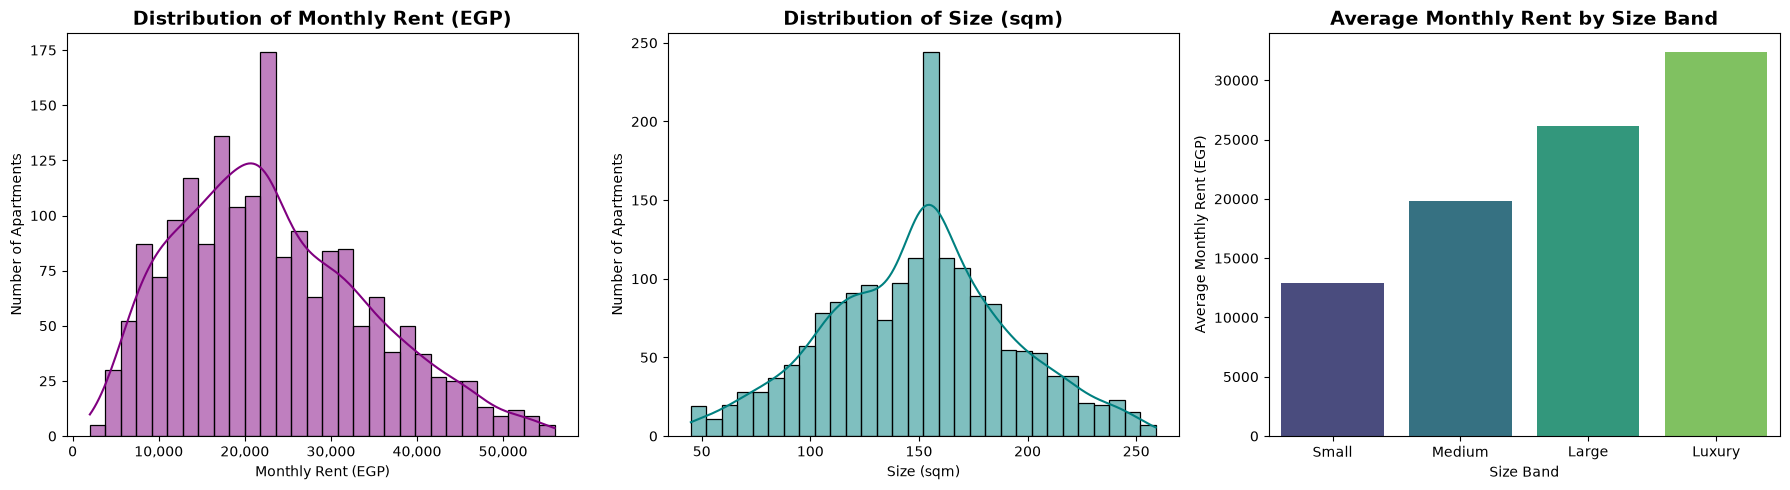

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df_rentals['monthly_rent_egp'], bins=30, kde=True, color='purple', ax=ax[0])
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax[0].set_title('Distribution of Monthly Rent (EGP)', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Monthly Rent (EGP)')
ax[0].set_ylabel('Number of Apartments')

sns.histplot(df_rentals['size_sqm'], bins=30, kde=True, color='teal', ax=ax[1])
ax[1].set_title('Distribution of Size (sqm)', fontsize=14, fontweight='bold')
ax[1].set_xlabel('Size (sqm)')
ax[1].set_ylabel('Number of Apartments')

size_avg_price = df_rentals.groupby('size_band')['monthly_rent_egp'].mean().reset_index()
sns.barplot(data=size_avg_price, x='size_band', y='monthly_rent_egp',palette='viridis', ax=ax[2])
ax[2].set_title('Average Monthly Rent by Size Band', fontsize=14, fontweight='bold')
ax[2].set_xlabel('Size Band')
ax[2].set_ylabel('Average Monthly Rent (EGP)')

plt.tight_layout()
plt.savefig('../outputs/charts/chart1.png', dpi=300)
plt.show()

### Identifying Districts with the Highest Price Momentum

- Calculate the average month-on-month price change (`price_delta`) for each district to identify rental price trends.
- Sort districts in descending order based on their average price changes.
- Select the top 10 districts with the highest average price momentum.
- Create a horizontal bar chart to compare price increases across these districts.
- Use color differentiation and gridlines to improve readability.
- Save the visualization as a high-resolution PNG image (300 DPI) and display it.

**Expected Output:**
- A horizontal bar chart showing the top 10 districts with the highest average monthly rental price increases.
- Districts ranked from highest to lowest average price change.
- Saved chart at `../outputs/charts/chart2.png`.

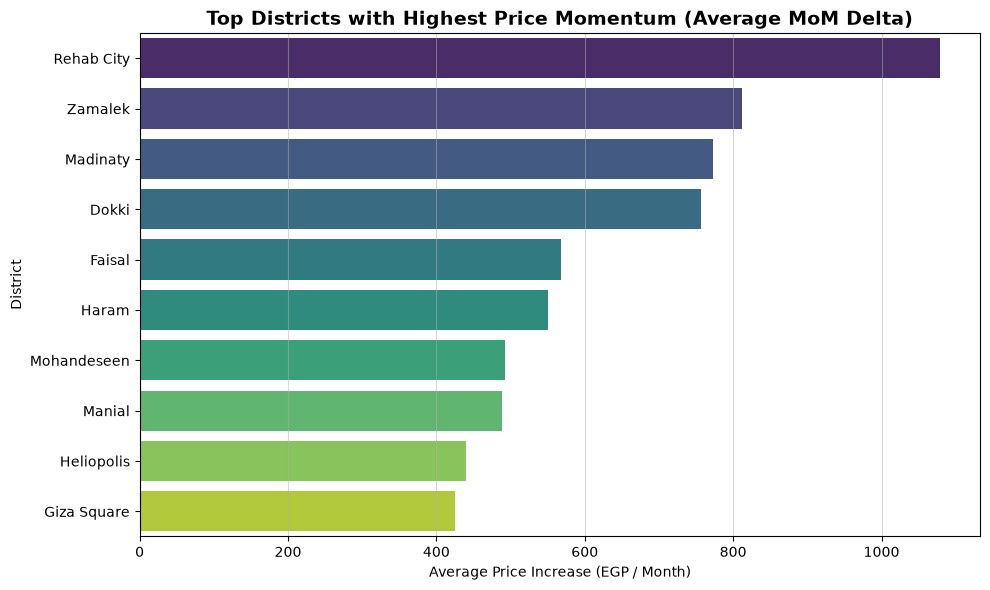

In [14]:
plt.figure(figsize=(10, 6))

top_momentum = monthly_avg.groupby('district', observed=True)['price_delta'].mean().reset_index()
top_momentum = top_momentum.sort_values(by='price_delta', ascending=False).head(10)

sns.barplot(
    data=top_momentum, 
    x='price_delta', 
    y='district', 
    palette='viridis',
    hue='district',
)

plt.title('Top Districts with Highest Price Momentum (Average MoM Delta)', fontsize=14, fontweight='bold')
plt.xlabel('Average Price Increase (EGP / Month)')
plt.ylabel('District', )
plt.grid(axis='x', alpha=0.5)
plt.tight_layout()

plt.savefig('../outputs/charts/chart2.png', dpi=300)
plt.show()

### Encoding Categorical Features

- Apply One-Hot Encoding to the `furnished` column using `pd.get_dummies()`.
- Convert furnishing categories into separate binary numerical columns to make them suitable for machine learning and numerical analysis.
- Use `drop_first=True` to avoid redundant dummy variables.
- Set `dtype=int` to represent encoded values as 0 and 1.
- Display the first 5 rows to verify the transformation.

**Expected Output:**
- The original `furnished` column is replaced with binary columns (e.g., `furnish_Semi-Furnished` and `furnish_Unfurnished`).
- Encoded values represented as 0 and 1.

In [15]:
df_rentals = pd.get_dummies(df_rentals, columns=['furnished'], prefix='furnish', drop_first=True, dtype=int)
df_rentals.head()

,listing_id,district,latitude,longitude,size_sqm,rooms,monthly_rent_egp,listing_date,population_density,avg_income_index,metro_access,price_per_sqm,year_month,monthly_rent_egp_monthly_avg,price_delta,price_pct_change,size_band,furnish_Semi-Furnished,furnish_Unfurnished
0,SKN00001,Heliopolis,30.0915,31.3158,160.0,3,25500.0,2026-01-23,19500,82.1,True,159.375000,2026-01,27500.000000,6100.000000,28.504673,Large,0,1
1,SKN00002,Dokki,30.0310,31.2209,206.0,4,40000.0,2025-12-01,42000,75.3,True,194.174757,2025-12,27071.428571,-1095.238095,-3.888419,Luxury,1,0
2,SKN00003,Giza Square,30.0193,31.2034,159.0,3,13500.0,2025-11-21,65000,48.6,True,84.905660,2025-11,19666.666667,7666.666667,63.888889,Large,0,1
3,SKN00005,Haram,29.9832,31.1553,132.0,3,22000.0,2026-03-08,85000,45.1,True,166.666667,2026-03,15000.000000,3166.666667,26.760563,Medium,0,0
4,SKN00006,6Th Of October,29.9796,30.9244,181.0,3,19500.0,2026-05-19,3100,65.0,False,107.734807,2026-05,20343.750000,2805.288462,15.995066,Large,0,1


### Correlation Analysis of Property Features

- Select relevant numerical columns, including rental prices, property size, number of rooms, population density, average income index, and price per square meter.
- Calculate the correlation matrix using `.corr()` to examine the strength and direction of relationships between numerical features.
- Visualize the correlation matrix using a heatmap with annotated correlation values for easier interpretation.
- Apply a color gradient to distinguish positive and negative correlations.
- Rotate x-axis labels for readability.
- Save the heatmap as a high-resolution PNG image (300 DPI) and display it.

**Expected Output:**
- A correlation heatmap showing relationships between numerical property features.
- Correlation coefficients displayed inside each cell.
- Saved chart at `../outputs/charts/chart2.png`.

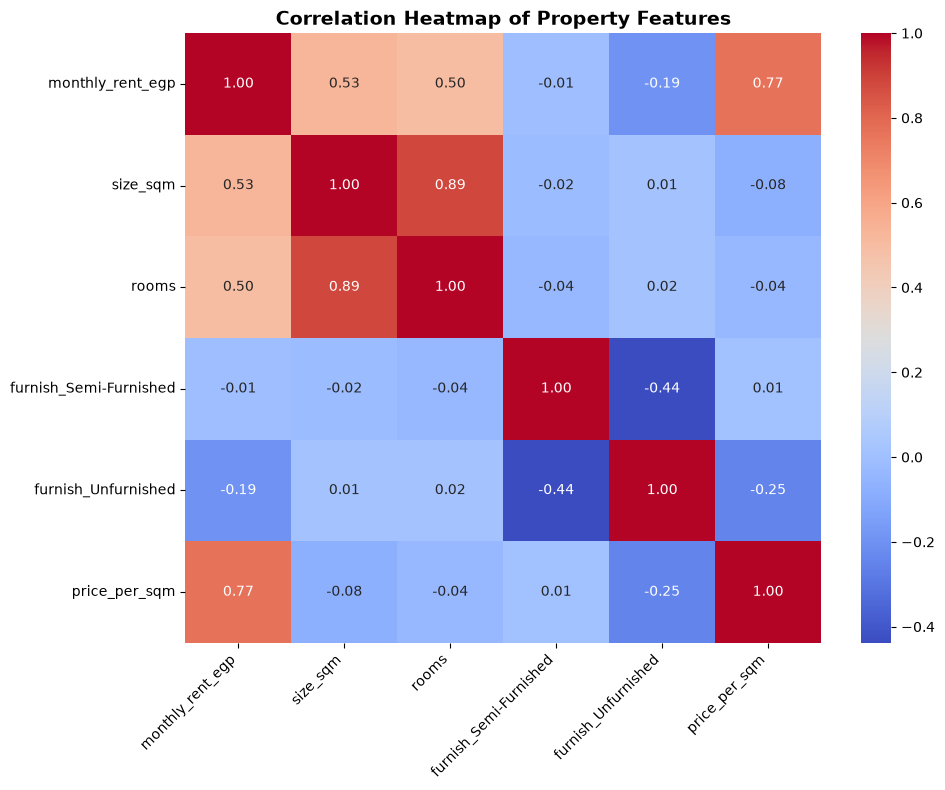

In [16]:
fig = plt.figure(figsize=(10, 8))

numeric_cols = ['monthly_rent_egp', 'size_sqm', 'rooms', 'furnish_Semi-Furnished', 'furnish_Unfurnished', 'price_per_sqm']
correlation_matrix = df_rentals[numeric_cols].corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Heatmap of Property Features', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig('../outputs/charts/chart3.png', dpi=300)
plt.show()



### Monthly Rent Distribution Across Districts

- Create a horizontal boxplot to compare monthly rental price distributions across different districts.
- Use `district` to group rental prices and identify differences in median rent, spread, and potential outliers.
- Apply distinct colors to differentiate districts.
- Format the x-axis values with comma separators for better readability.
- Add gridlines and adjust the layout for clearer visualization.
- Save the chart as a high-resolution PNG image (300 DPI) and display it.

**Expected Output:**
- A boxplot comparing monthly rent distributions across districts.
- Visualization of median prices, interquartile ranges, and potential outliers.
- Saved chart at `../outputs/charts/chart3.png`.

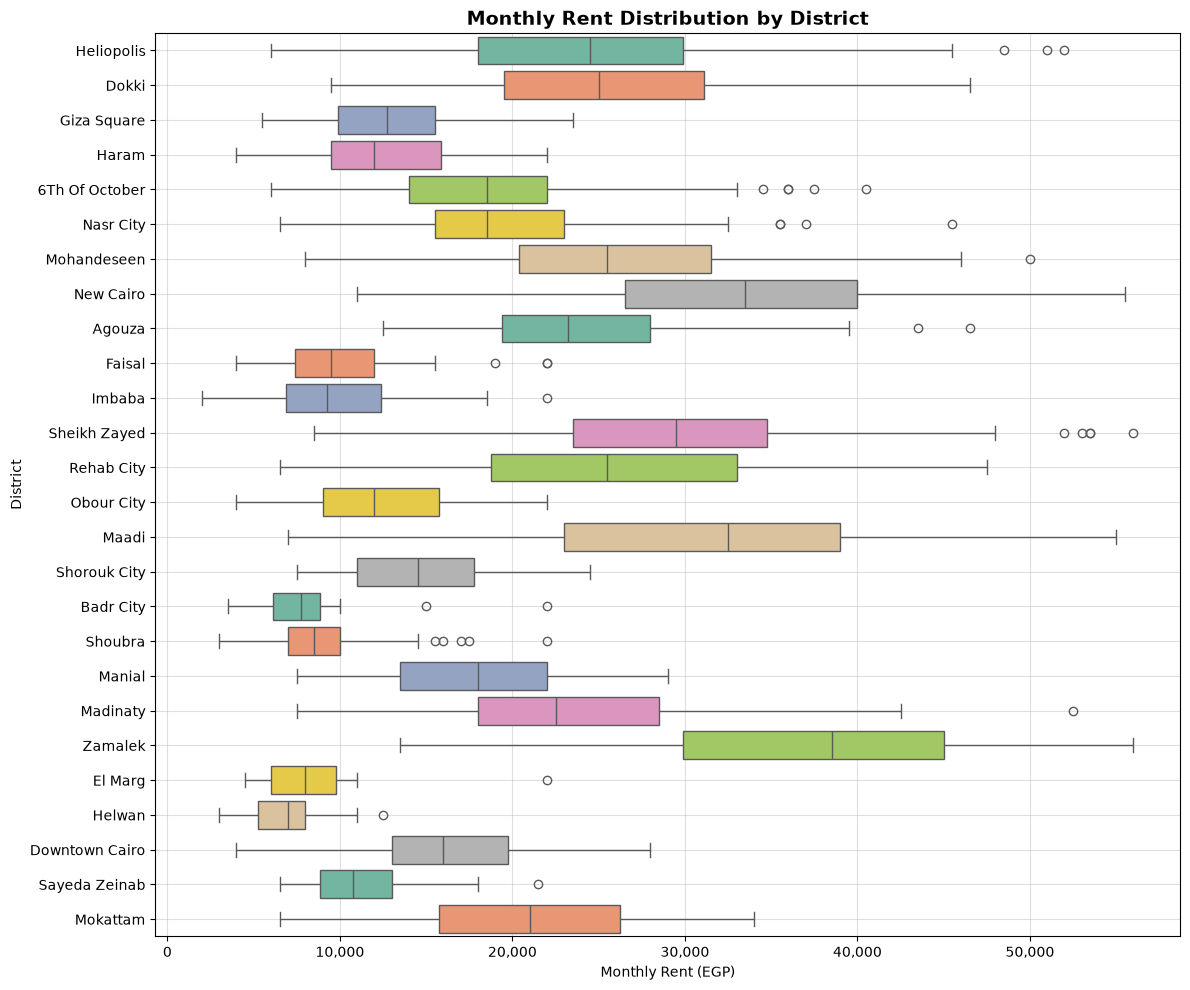

In [17]:
fig = plt.figure(figsize=(12, 10))
sns.boxplot(data=df_rentals, x='monthly_rent_egp', y='district', palette='Set2', hue='district')
plt.title('Monthly Rent Distribution by District', fontsize=14, fontweight='bold')
plt.xlabel('Monthly Rent (EGP)')
plt.ylabel('District')
plt.gca().xaxis.set_major_formatter('{x:,.0f}')

plt.grid(True, alpha=0.4)
plt.tight_layout()

plt.savefig('../outputs/charts/chart4.png', dpi=300)
plt.show()

### Interactive Cairo Rental Price Map

- Aggregate rental data by district to calculate average monthly rent, average price per square meter, and median latitude and longitude.
- Create an interactive map using Plotly to visualize rental price variations across Cairo districts.
- Represent average monthly rent through marker size and color using the Viridis color scale.
- Display district names, average monthly rent, and average price per square meter in hover information.
- Set Cairo as the map center and adjust the zoom level for a clearer geographical view.
- Export the interactive map as an HTML file and display it.

**Expected Output:**
- An interactive map showing rental price variations across Cairo districts.
- Larger and more intensely colored markers represent districts with higher average rents.
- Hover information displaying district-level rental statistics.
- Saved interactive map at `../outputs/interactive_map.html`.

In [18]:
district_map_data = df_rentals.groupby('district', observed=True).agg({
    'monthly_rent_egp': 'mean',
    'price_per_sqm': 'mean',
    'latitude': 'median',  
    'longitude': 'median' 
}).reset_index()

fig = px.scatter_map(
    district_map_data,
    lat='latitude',
    lon='longitude',
    size='monthly_rent_egp',
    color='monthly_rent_egp',
    color_continuous_scale='Viridis',
    hover_name='district',
    hover_data=['monthly_rent_egp', 'price_per_sqm'],
    title='Interactive Cairo Rental Price Map (Micro-Markets)'
)

fig.update_layout(
    map_style='open-street-map',
    map=dict(center=dict(lat=30.0444, lon=31.2357), zoom=10)
)

fig.write_html('../outputs/interactive_map.html')
fig.show()
